# P05: a deeper CNN

ADR 0008 found that training the CNN for 100 epochs helps (`cnn_longer`), but that the network still cannot fit its own
training images (68% train accuracy). Our guess is that it is too small, and that it sees too little of the picture at a time:
with three convolution blocks, each unit before the final averaging looks at a patch of only 22 x 22 pixels of the 64 x 64
image, and the averaging then forgets where the patch was.

A **fourth block** raises the patch to 46 x 46 pixels and halves the feature map (8 x 8 to 4 x 4) before the averaging.

| run | convolution blocks | filters | epochs |
|---|---|---|---|
| `cnn_longer` (P04, reference) | 3 | 16, 32, 64 | 100 |
| `cnn_deeper` | 4 | 16, 32, 64, 128 | 100 |

Everything else is identical: same data, same split, same seed (0), no batch norm, same training loop. We use one seed to
start; if the result is clearly better, it is repeated with 5 seeds. As agreed in ADR 0008, we judge it on **smoother
measures** (last epoch, mean of the last 10 epochs, score at the lowest validation loss), not on the best epoch alone.
**The test set (museum B) is not used here** (ADR 0003).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from deep_learning_project_waerniers_lamy_mahieddine.vision.utils import build_cnn, load_result, run_experiment, summary

# The CNN of P04 trained for 100 epochs (the reference), written out in full.
BASE = {
    "model": "cnn",
    "image_size": 64,
    "conv_channels": [16, 32, 64],
    "kernel_size": 3,
    "batch_norm": False,
    "dropout": 0.0,
    "epochs": 100,
    "lr": 1e-3,
    "batch_size": 64,
    "weight_decay": 0.0,
    "seed": 0,
}

# The only change: a fourth convolution block.
CONFIG = {**BASE, "conv_channels": [16, 32, 64, 128]}
NAME = "cnn_deeper"

runs_table = summary()


def saved_run(name):
    """The earliest saved run with this name (a run logged twice has identical numbers)."""
    rows = runs_table[runs_table["name"] == name].sort_values("date")
    return load_result(rows["file"].iloc[0])


cnn_first = saved_run("cnn_first")
cnn_longer = saved_run("cnn_longer")

# Safety check: BASE is exactly the config of the reference run, so only the fourth block can explain a difference.
assert cnn_longer["config"] == BASE

## 1. The model described by the config

We build it once to look at it: the shape of the image after each layer, and the number of weights.

In [2]:
model = build_cnn(CONFIG)

x = torch.zeros(1, 3, CONFIG["image_size"], CONFIG["image_size"])  # one blank image, to follow its shape
for layer in model:
    x = layer(x)
    print(f"{layer.__class__.__name__:18s} -> {tuple(x.shape)}")

print("\nparameters:", sum(p.numel() for p in model.parameters()),
      "| cnn_longer:", cnn_longer["n_params"], "| dense baseline: 393989")

Conv2d             -> (1, 16, 64, 64)
ReLU               -> (1, 16, 64, 64)
MaxPool2d          -> (1, 16, 32, 32)
Conv2d             -> (1, 32, 32, 32)
ReLU               -> (1, 32, 32, 32)
MaxPool2d          -> (1, 32, 16, 16)
Conv2d             -> (1, 64, 16, 16)
ReLU               -> (1, 64, 16, 16)
MaxPool2d          -> (1, 64, 8, 8)
Conv2d             -> (1, 128, 8, 8)
ReLU               -> (1, 128, 8, 8)
MaxPool2d          -> (1, 128, 4, 4)
AdaptiveAvgPool2d  -> (1, 128, 1, 1)
Flatten            -> (1, 128)
Dropout            -> (1, 128)
Linear             -> (1, 5)

parameters: 98085 | cnn_longer: 23909 | dense baseline: 393989


## 2. Run the experiment

100 epochs, about 7 minutes. One seed: `seeds=1`.

In [3]:
outcome = run_experiment(NAME, CONFIG, seeds=1)

98085 parameters | before training: loss 1.611 (ln 5 = 1.609), accuracy 19.9%
epoch   1 | train loss 1.485 acc 0.321 | val loss 1.524 acc 0.275
epoch   5 | train loss 1.265 acc 0.436 | val loss 1.321 acc 0.404
epoch  10 | train loss 1.100 acc 0.554 | val loss 1.227 acc 0.483
epoch  15 | train loss 1.019 acc 0.602 | val loss 1.179 acc 0.537
epoch  20 | train loss 0.922 acc 0.637 | val loss 1.160 acc 0.535
epoch  25 | train loss 0.844 acc 0.672 | val loss 1.136 acc 0.550
epoch  30 | train loss 0.750 acc 0.718 | val loss 1.110 acc 0.562
epoch  35 | train loss 0.680 acc 0.746 | val loss 1.136 acc 0.554
epoch  40 | train loss 0.600 acc 0.785 | val loss 1.163 acc 0.562
epoch  45 | train loss 0.474 acc 0.846 | val loss 1.199 acc 0.562
epoch  50 | train loss 0.371 acc 0.878 | val loss 1.261 acc 0.590
epoch  55 | train loss 0.354 acc 0.880 | val loss 1.402 acc 0.579
epoch  60 | train loss 0.223 acc 0.942 | val loss 1.480 acc 0.581
epoch  65 | train loss 0.191 acc 0.945 | val loss 1.702 acc 0.57

## 3. Learning curves

Compared with the first CNN (30 epochs) and `cnn_longer`. Things to look at: does the validation accuracy rise above the
reference, is the train accuracy now higher (the network fits the training images better), and does the gap between the two
grow (overfitting)?

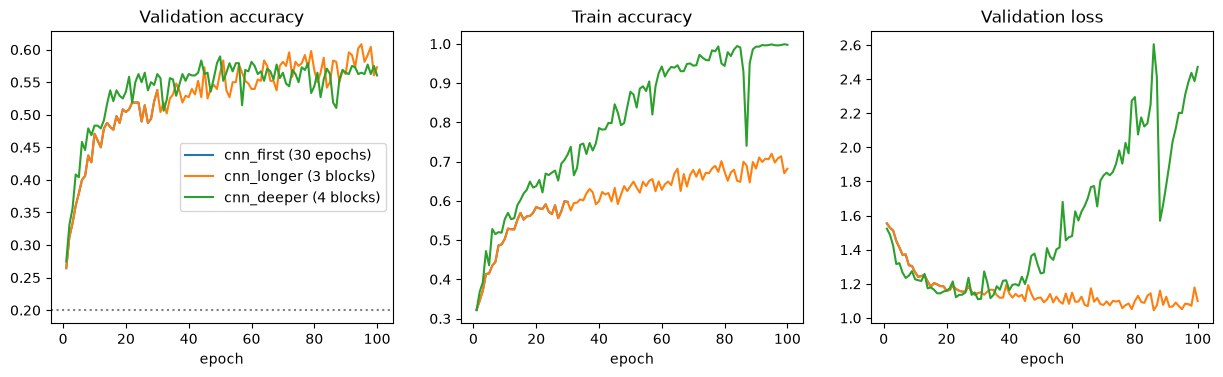

In [4]:
histories = {
    "cnn_first (30 epochs)": cnn_first["history"],
    "cnn_longer (3 blocks)": cnn_longer["history"],
    "cnn_deeper (4 blocks)": outcome["result"]["history"],
}

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for label, h in histories.items():
    epochs = range(1, len(h["val_acc"]) + 1)
    axes[0].plot(epochs, h["val_acc"], label=label)
    axes[1].plot(epochs, h["train_acc"], label=label)
    axes[2].plot(epochs, h["val_loss"], label=label)
axes[0].set_title("Validation accuracy")
axes[1].set_title("Train accuracy")
axes[2].set_title("Validation loss")
axes[0].axhline(0.2, color="grey", linestyle=":")
for ax in axes:
    ax.set_xlabel("epoch")
axes[0].legend()
plt.show()

## 4. The smoother measures

The best epoch is the best of many noisy epochs, so it flatters a model. We also look at the last epoch, the average of the
last 10 epochs, the score at the epoch where the validation loss is lowest, and the swing (how much the validation accuracy
moves from one epoch to the next). The first CNN only trained for 30 epochs and was still rising, so its "mean of last 10"
is not comparable.

In [5]:
def measures(history):
    val = np.array(history["val_acc"])
    loss = np.array(history["val_loss"])
    return {
        "best epoch (%)": 100 * val.max(),
        "last epoch (%)": 100 * val[-1],
        "mean of last 10 (%)": 100 * val[-10:].mean(),
        "at lowest val loss (%)": 100 * val[loss.argmin()],
        "swing (points)": 100 * np.diff(val[-10:]).std(),
        "train acc, last (%)": 100 * history["train_acc"][-1],
        "gap train - val, last (points)": 100 * (history["train_acc"][-1] - val[-1]),
        "lowest val loss": loss.min(),
    }


pd.DataFrame({label: measures(h) for label, h in histories.items()}).round(1)

,cnn_first (30 epochs),cnn_longer (3 blocks),cnn_deeper (4 blocks)
best epoch (%),53.8,60.8,59.0
last epoch (%),53.8,57.3,56.0
mean of last 10 (%),51.1,58.8,56.8
at lowest val loss (%),52.1,58.3,56.2
swing (points),1.9,2.2,1.1
"train acc, last (%)",59.7,68.2,99.7
"gap train - val, last (points)",6.0,10.9,43.7
lowest val loss,1.1,1.0,1.1


## 5. By genre

Each genre has only 96 validation images, so a single value moves a lot from one run to another.

In [6]:
confusions = {"cnn_longer": cnn_longer["val_confusion"], "cnn_deeper": outcome["confusion"]}
per_genre = pd.DataFrame({name: {genre: c.loc[genre, genre] / c.loc[genre].sum() for genre in c.index}
                          for name, c in confusions.items()}).round(2)
display(per_genre)
display(outcome["confusion"])

,cnn_longer,cnn_deeper
cityscape,0.65,0.57
landscape,0.61,0.61
portrait,0.61,0.65
religious_painting,0.59,0.51
still_life,0.57,0.60


predicted,cityscape,landscape,portrait,religious_painting,still_life
true genre,,,,,
cityscape,55,25,1,6,9
landscape,24,59,2,3,8
portrait,7,3,62,15,9
religious_painting,11,5,21,49,10
still_life,8,9,14,7,58


## 6. Repeat with 5 seeds

Only if the deeper CNN is clearly better than `cnn_longer` on the smoother measures (by more than the swing, about 2 points).
Set `CONFIRM = True` and run the cell: about 35 minutes. Leave it at `False` until we have looked at the results above.

In [ ]:
CONFIRM = False

if CONFIRM:
    run_experiment(NAME + "_5seeds", CONFIG, seeds=5)

98085 parameters | before training: loss 1.611 (ln 5 = 1.609), accuracy 19.9%
epoch   1 | train loss 1.485 acc 0.321 | val loss 1.524 acc 0.275
epoch   5 | train loss 1.265 acc 0.436 | val loss 1.321 acc 0.404
epoch  10 | train loss 1.100 acc 0.554 | val loss 1.227 acc 0.483
epoch  15 | train loss 1.019 acc 0.602 | val loss 1.179 acc 0.537
epoch  20 | train loss 0.922 acc 0.637 | val loss 1.160 acc 0.535
epoch  25 | train loss 0.844 acc 0.672 | val loss 1.136 acc 0.550
epoch  30 | train loss 0.750 acc 0.718 | val loss 1.110 acc 0.562
epoch  35 | train loss 0.680 acc 0.746 | val loss 1.136 acc 0.554
epoch  40 | train loss 0.600 acc 0.785 | val loss 1.163 acc 0.562
epoch  45 | train loss 0.474 acc 0.846 | val loss 1.199 acc 0.562
epoch  50 | train loss 0.371 acc 0.878 | val loss 1.261 acc 0.590
epoch  55 | train loss 0.354 acc 0.880 | val loss 1.402 acc 0.579
epoch  60 | train loss 0.223 acc 0.942 | val loss 1.480 acc 0.581
epoch  65 | train loss 0.191 acc 0.945 | val loss 1.702 acc 0.57

## What we see

Seed 0 for the first two rows, 100 epochs each. The last row repeats `cnn_deeper` with 5 seeds.

| run | weights | best epoch | last epoch | mean of last 10 | at lowest val loss | train acc, last | val loss, lowest to last |
|---|---|---|---|---|---|---|---|
| `cnn_longer` (3 blocks) | 23,909 | **60.8%** (95) | 57.3% | **58.8%** | 58.3% | 68.2% | 1.05 to 1.10 |
| `cnn_deeper` (4 blocks) | 98,085 | 59.0% (50) | 56.0% | 56.8% | 56.2% | **99.7%** | 1.11 to **2.47** |
| `cnn_deeper`, 5 seeds | 98,085 | **58.4%** mean (std 1.1; 56.5% to 59.2%) | | | | | |

- **No gain on validation.** On every smoother measure the deeper CNN is 1 to 2 points *below* `cnn_longer`, within the noise
  (about +/- 4.4 points on 480 images). The 5 seeds confirm that seed 0 was representative: 59.0%, 58.3%, 59.2%, 56.5% and
  59.0%. The fourth block did not help. We did not repeat `cnn_longer` with 5 seeds, so that comparison rests on its seed 0.
- **Capacity was not the limit any more.** The deeper CNN fits its training images almost perfectly (99.7%, against 68% for
  `cnn_longer`). The extra capacity went into memorising them: the gap between train and validation is 44 points, and the
  validation loss rises from 1.11 (epoch 30) to 2.47 (epoch 100), which means confident wrong answers.
- **It learns faster at first.** Validation accuracy at epochs 20, 30 and 50 is 53.5%, 56.2% and 59.0%, against 50.4%, 53.8%
  and 56.5% for `cnn_longer`. It then stops improving and slowly declines as it memorises.
- **The best epoch is unreliable for a model that overfits.** Over the 5 seeds it falls anywhere between epoch 32 and epoch 99.
- **Our guess about the field of view is not supported.** Seeing 46 x 46 pixels instead of 22 x 22 did not raise the validation
  score. The bottleneck is now generalisation (only 1,920 training images), not depth.
- **A run takes about 9 to 10 minutes**, not the 7 estimated from two short epochs.

Next (ADR 0008): since the deeper CNN does not clearly beat `cnn_longer`, we stop tuning the small CNN and move to the pretrained
ResNet (P06). If we came back to the small CNN, the levers would be regularisation (dropout, weight decay) and data
augmentation, not more layers.

# Test on the latest best saved models

In [ ]:
from deep_learning_project_waerniers_lamy_mahieddine.vision.utils import score_on_test, summary

for stem in ["cnn_longer_2026-10-22_13-07-48",       # best CNN
             "cnn_first_2026-10-21_19-54-39",        # first CNN
             "cnn_deeper_2026-10-22_14-39-16",       # 4 blocks
             "dense_baseline_2026-10-21_17-29-52"]:  # dense baseline
    score_on_test(stem)

summary()[["name", "best_val_acc", "test_acc", "test_loss"]]